# Análisis de Europarl (formato XML)

Objetivo: analizar los ~3,656 archivos de debates parlamentarios en `data/Europarl/en/` para seleccionar **1,000 debates representativos** que cubran diversidad de tamaños y temas para el pipeline de traducción.

## Contenido
1. Carga y parsing de archivos
2. Distribución de longitudes (palabras y caracteres)
3. Clasificación temática automática (heurística por keywords en títulos)
4. Estadísticas de estructura (speakers por debate)
5. Estimación de costos
6. Criterios de selección y generación del subset
7. Exportación a `data/Europarl/selected/`

In [1]:
import re
import shutil
import os
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

print(f"Inicio")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})

EN_DIR = Path("../data/Europarl/en")

# Usar os.scandir (mucho más rápido que Path.glob en Windows)
print(f"Escaneando Directorio: {EN_DIR}")
entries = []
total_size = 0
with os.scandir(EN_DIR) as it:
    for entry in it:
        if entry.name.endswith(".txt") and entry.is_file():
            entries.append(entry.name)
            total_size += entry.stat().st_size

entries.sort()
files = [EN_DIR / name for name in entries]

print(f"Directorio: {EN_DIR}")
print(f"Total archivos: {len(files):,}")
print(f"Tamaño total: {total_size / (1024**2):.1f} MB")

Inicio
Escaneando Directorio: ../data/Europarl/en
Directorio: ../data/Europarl/en
Total archivos: 3,656
Tamaño total: 56.6 MB


## 1. Carga y parsing de archivos

Cada archivo `.txt` contiene un debate con tags `<CHAPTER>`, `<SPEAKER>` y `<P>`.

In [2]:
def parse_europarl(filepath: Path) -> dict:
    """Parsea un archivo Europarl y extrae metadatos."""
    text = filepath.read_text(encoding="utf-8", errors="replace")
    
    # Extraer CHAPTER ID y título
    ch_match = re.search(r'<CHAPTER\s+ID="([^"]*)">', text)
    chapter_id = ch_match.group(1) if ch_match else ""
    
    # Título: texto entre <CHAPTER> y el primer <SPEAKER>
    title = ""
    ch_end = text.find(">", text.find("<CHAPTER")) + 1 if "<CHAPTER" in text else 0
    next_tag = text.find("<", ch_end)
    if next_tag > ch_end:
        title = text[ch_end:next_tag].strip()
    
    # Texto sin tags (para conteos)
    text_only = re.sub(r'<[^>]+>', '', text).strip()
    text_only = re.sub(r'\n{3,}', '\n\n', text_only)
    
    # Speakers
    speakers = re.findall(r'<SPEAKER[^>]*NAME="([^"]*)"', text)
    unique_speakers = len(set(speakers))
    
    # Idiomas de speakers
    languages = re.findall(r'LANGUAGE="([^"]*)"', text)
    
    return {
        "file": filepath.name,
        "chapter_id": chapter_id,
        "titulo": title,
        "chars_total": len(text),
        "chars_texto": len(text_only),
        "palabras": len(text_only.split()),
        "speakers_total": len(speakers),
        "speakers_unicos": unique_speakers,
        "idiomas": list(set(languages)) if languages else [],
        "n_idiomas": len(set(languages)) if languages else 0,
        "paragraphs": text.count("<P>"),
    }

# Parsear todos los archivos
data = [parse_europarl(f) for f in files]
df = pd.DataFrame(data)

print(f"DataFrame creado: {df.shape}")
print(f"Archivos con contenido (> 50 chars texto): {(df['chars_texto'] > 50).sum():,}")
print(f"Archivos vacíos/tiny (<= 50 chars texto): {(df['chars_texto'] <= 50).sum():,}")
df.head(10)

DataFrame creado: (3656, 11)
Archivos con contenido (> 50 chars texto): 2,802
Archivos vacíos/tiny (<= 50 chars texto): 854


,file,chapter_id,titulo,chars_total,chars_texto,palabras,speakers_total,speakers_unicos,idiomas,n_idiomas,paragraphs
0,ep-09-05-07-002.txt,002,,51,31,4,0,0,[],0,0
1,ep-09-05-07-009-01.txt,009-01,1. Gender mainstreaming in EU external relatio...,1346,1270,202,1,1,[],0,5
2,ep-09-05-07-009-03.txt,009-03,3. Financial aspects of the Lisbon Treaty (,1336,1242,231,1,1,[FR],1,4
3,ep-09-05-07-009-04.txt,009-04,,113,90,14,0,0,[],0,0
4,ep-09-05-07-009-06.txt,009-06,,160,137,20,0,0,[],0,0
5,ep-09-05-07-009-09.txt,009-09,,193,170,22,0,0,[],0,0
6,ep-09-05-07-009-10.txt,009-10,,116,93,12,0,0,[],0,0
7,ep-09-05-07-009-12.txt,009-12,,194,171,22,0,0,[],0,0
8,ep-09-05-07-009-13.txt,009-13,13. Situation in the Republic of Moldova,763,608,104,2,2,[],0,2
9,ep-09-05-07-009-15.txt,009-15,,71,48,9,0,0,[],0,0


## 2. Estadísticas descriptivas

In [3]:
# Filtrar solo archivos con contenido real
df_content = df[df["chars_texto"] > 50].copy()

print("=" * 60)
print("ESTADÍSTICAS GENERALES (archivos con contenido)")
print("=" * 60)
print(f"Total archivos:         {len(df):,}")
print(f"Con contenido (>50ch):  {len(df_content):,}")
print(f"Total palabras:         {df_content['palabras'].sum():,}")
print(f"Total caracteres:       {df_content['chars_texto'].sum():,}")
print()
print(df_content[["palabras", "chars_texto", "speakers_total", "speakers_unicos", "paragraphs"]].describe().round(1).to_string())
print()
print("-" * 60)
print("PERCENTILES DE PALABRAS")
print("-" * 60)
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    val = df_content["palabras"].quantile(p / 100)
    print(f"  P{p:>2}: {val:>8,.0f} palabras")

ESTADÍSTICAS GENERALES (archivos con contenido)
Total archivos:         3,656
Con contenido (>50ch):  2,802
Total palabras:         9,319,989
Total caracteres:       56,504,132

       palabras  chars_texto  speakers_total  speakers_unicos  paragraphs
count    2802.0       2802.0          2802.0           2802.0      2802.0
mean     3326.2      20165.6            15.9             10.2        28.5
std      8368.3      51711.5            51.3             20.6        54.7
min         6.0         51.0             0.0              0.0         0.0
25%        10.0         66.0             0.0              0.0         0.0
50%        22.0        137.0             1.0              1.0         1.0
75%      3927.0      23717.5            16.0             13.8        38.8
max    131459.0     829969.0           899.0            187.0       509.0

------------------------------------------------------------
PERCENTILES DE PALABRAS
------------------------------------------------------------
  P 1:   

In [4]:
# Tabla de rangos de tamaño
bins = [0, 100, 300, 500, 1000, 2000, 5000, 10000, 20000, 50000, float("inf")]
labels = ["<100", "100-300", "300-500", "500-1K", "1K-2K", "2K-5K", "5K-10K", "10K-20K", "20K-50K", "50K+"]
df_content["rango_palabras"] = pd.cut(df_content["palabras"], bins=bins, labels=labels, right=False)

tabla_rangos = df_content.groupby("rango_palabras", observed=False).agg(
    archivos=("file", "count"),
    palabras_total=("palabras", "sum"),
    media_palabras=("palabras", "mean"),
).reset_index()
tabla_rangos["pct_archivos"] = (tabla_rangos["archivos"] / len(df_content) * 100).round(1)
tabla_rangos["pct_palabras"] = (tabla_rangos["palabras_total"] / df_content["palabras"].sum() * 100).round(1)

print("DISTRIBUCIÓN POR RANGO DE TAMAÑO")
print("=" * 80)
print(tabla_rangos.to_string(index=False))

DISTRIBUCIÓN POR RANGO DE TAMAÑO
rango_palabras  archivos  palabras_total  media_palabras  pct_archivos  pct_palabras
          <100      1594           26572       16.670013          56.9           0.3
       100-300       212           36838      173.764151           7.6           0.4
       300-500        76           29121      383.171053           2.7           0.3
        500-1K        56           39333      702.375000           2.0           0.4
         1K-2K        40           59439     1485.975000           1.4           0.6
         2K-5K       223          810233     3633.331839           8.0           8.7
        5K-10K       324         2428184     7494.395062          11.6          26.1
       10K-20K       188         2482397    13204.239362           6.7          26.6
       20K-50K        69         1998204    28959.478261           2.5          21.4
          50K+        20         1409668    70483.400000           0.7          15.1


## 3. Distribución de longitudes

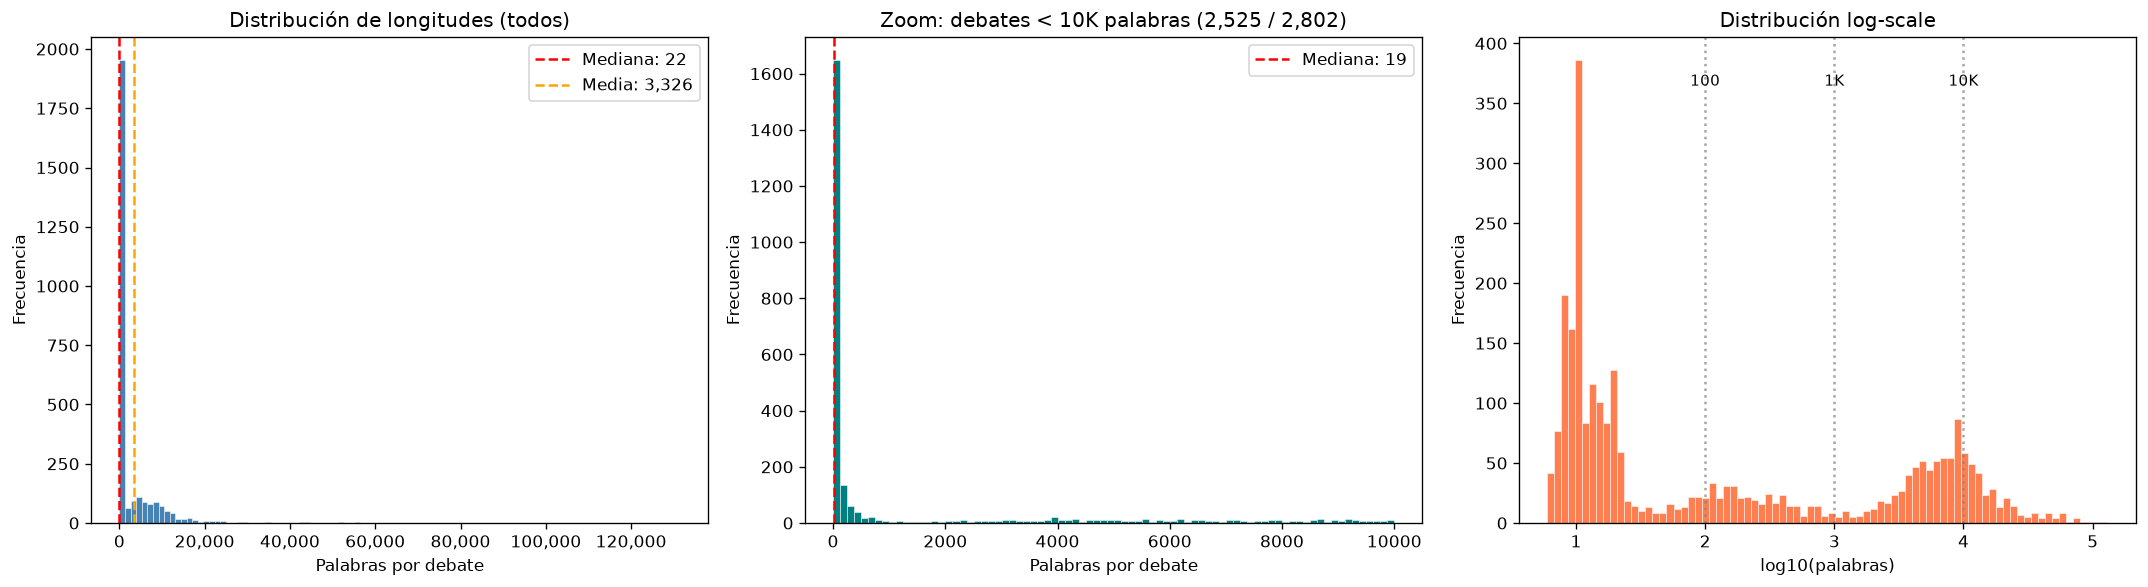

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3a. Histograma general
ax = axes[0]
ax.hist(df_content["palabras"], bins=100, color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por debate")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de longitudes (todos)")
ax.axvline(df_content["palabras"].median(), color="red", linestyle="--", label=f'Mediana: {df_content["palabras"].median():,.0f}')
ax.axvline(df_content["palabras"].mean(), color="orange", linestyle="--", label=f'Media: {df_content["palabras"].mean():,.0f}')
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# 3b. Zoom (< 10K palabras)
ax = axes[1]
subset = df_content[df_content["palabras"] < 10000]
ax.hist(subset["palabras"], bins=80, color="teal", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Palabras por debate")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Zoom: debates < 10K palabras ({len(subset):,} / {len(df_content):,})")
ax.axvline(subset["palabras"].median(), color="red", linestyle="--", label=f'Mediana: {subset["palabras"].median():,.0f}')
ax.legend()

# 3c. Log-scale
ax = axes[2]
ax.hist(np.log10(df_content["palabras"].clip(lower=1)), bins=80, color="coral", edgecolor="white", linewidth=0.3)
ax.set_xlabel("log10(palabras)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución log-scale")
for val, label in [(2, "100"), (3, "1K"), (4, "10K")]:
    ax.axvline(val, color="gray", linestyle=":", alpha=0.7)
    ax.text(val, ax.get_ylim()[1] * 0.9, label, ha="center", fontsize=9)

plt.tight_layout()
plt.show()

## 4. Clasificación temática (heurística por keywords en títulos)

Los títulos de los debates son descriptivos del tema legislativo. Clasificamos usando keywords parlamentarios.

In [6]:
TOPIC_KEYWORDS = {
    "economy_finance": [
        "economic", "economy", "financial", "budget", "fiscal", "tax", "taxation",
        "monetary", "euro", "eurozone", "banking", "bank", "debt", "deficit",
        "growth", "inflation", "investment", "market", "stock", "credit",
        "accounting", "audit", "expenditure", "revenue",
    ],
    "trade_market": [
        "trade", "trading", "import", "export", "tariff", "customs", "wto",
        "single market", "internal market", "competition", "antitrust",
        "dumping", "free trade", "bilateral", "mercosur", "nafta",
        "commercial", "commodity", "goods",
    ],
    "environment_energy": [
        "environment", "climate", "emission", "carbon", "co2", "renewable",
        "energy", "nuclear", "oil", "gas", "fuel", "pollution", "waste",
        "recycling", "biodiversity", "conservation", "natura 2000",
        "water", "marine", "ocean", "offshore", "green", "sustainable",
    ],
    "agriculture_food": [
        "agriculture", "agricultural", "farm", "food", "fisheries", "fishing",
        "rural", "crop", "livestock", "wine", "milk", "sugar", "tobacco",
        "organic", "gmo", "animal welfare", "veterinary", "beef", "poultry",
        "plant health", "pesticide", "hops",
    ],
    "foreign_affairs": [
        "foreign", "external", "enlargement", "neighbourhood", "partnership",
        "diplomacy", "sanctions", "embargo", "middle east", "africa", "asia",
        "russia", "china", "turkey", "ukraine", "afghanistan", "iraq", "iran",
        "balkans", "mediterranean", "latin america", "caribbean", "summit",
        "accession", "candidate", "third countr",
    ],
    "human_rights": [
        "human rights", "fundamental rights", "freedom", "discrimination",
        "equality", "gender", "women", "minority", "racism", "xenophob",
        "asylum", "refugee", "migra", "death penalty", "torture", "prison",
        "child", "disability", "charter of fundamental",
    ],
    "justice_security": [
        "justice", "judicial", "court", "criminal", "police", "europol",
        "terrorism", "security", "border", "schengen", "visa", "frontex",
        "organised crime", "fraud", "corruption", "money laundering",
        "data protection", "privacy", "surveillance", "cybersecur",
    ],
    "health_consumer": [
        "health", "medical", "pharmaceutical", "drug", "disease", "pandemic",
        "vaccine", "patient", "hospital", "consumer", "safety",
        "labelling", "tobacco", "alcohol", "cosmetic",
    ],
    "transport_infrastructure": [
        "transport", "railway", "rail", "road", "aviation", "air traffic",
        "maritime", "shipping", "port", "infrastructure", "trans-european",
        "motorway", "tunnel", "bridge", "passenger",
    ],
    "social_employment": [
        "employment", "unemployment", "worker", "labour", "working time",
        "social", "pension", "welfare", "poverty", "inclusion",
        "education", "training", "youth", "erasmus", "skill",
        "cohesion", "structural fund", "regional",
    ],
    "institutional": [
        "parliament", "commission", "council", "treaty", "constitution",
        "lisbon", "institutional", "intergovernmental", "codecision",
        "comitology", "transparency", "governance", "ombudsman",
        "vote", "agenda", "minutes", "sitting", "session",
        "rule of procedure", "mandate", "presidency",
    ],
    "technology_digital": [
        "digital", "internet", "electronic", "e-commerce", "telecom",
        "spectrum", "broadband", "roaming", "software", "cyber",
        "innovation", "research", "science", "space", "satellite",
        "galileo", "patent", "intellectual property",
    ],
    "development_aid": [
        "development", "aid", "cooperation", "humanitarian", "poverty",
        "millennium", "acp", "lome", "cotonou", "edf",
        "developing countr", "least developed",
    ],
    "defence_military": [
        "defence", "defense", "military", "army", "nato", "weapon",
        "arms", "disarmament", "peacekeeping", "crisis management",
        "common security", "esdp", "csdp",
    ],
}

def clasificar_debate(titulo: str) -> str:
    titulo_lower = titulo.lower()
    scores = {}
    for topic, keywords in TOPIC_KEYWORDS.items():
        score = sum(1 for kw in keywords if kw in titulo_lower)
        if score > 0:
            scores[topic] = score
    if not scores:
        return "other"
    return max(scores, key=scores.get)

df_content["tema"] = df_content["titulo"].apply(clasificar_debate)

tema_counts = df_content["tema"].value_counts()
print("DISTRIBUCIÓN TEMÁTICA")
print("=" * 55)
for tema, count in tema_counts.items():
    pct = count / len(df_content) * 100
    print(f"  {tema:<28} {count:>5,}  ({pct:>5.1f}%)")
print(f"  {'TOTAL':<28} {len(df_content):>5,}")

DISTRIBUCIÓN TEMÁTICA
  other                        1,646  ( 58.7%)
  institutional                  408  ( 14.6%)
  economy_finance                277  (  9.9%)
  foreign_affairs                 87  (  3.1%)
  trade_market                    72  (  2.6%)
  environment_energy              51  (  1.8%)
  human_rights                    48  (  1.7%)
  transport_infrastructure        45  (  1.6%)
  development_aid                 35  (  1.2%)
  justice_security                35  (  1.2%)
  agriculture_food                32  (  1.1%)
  social_employment               28  (  1.0%)
  health_consumer                 24  (  0.9%)
  technology_digital              11  (  0.4%)
  defence_military                 3  (  0.1%)
  TOTAL                        2,802


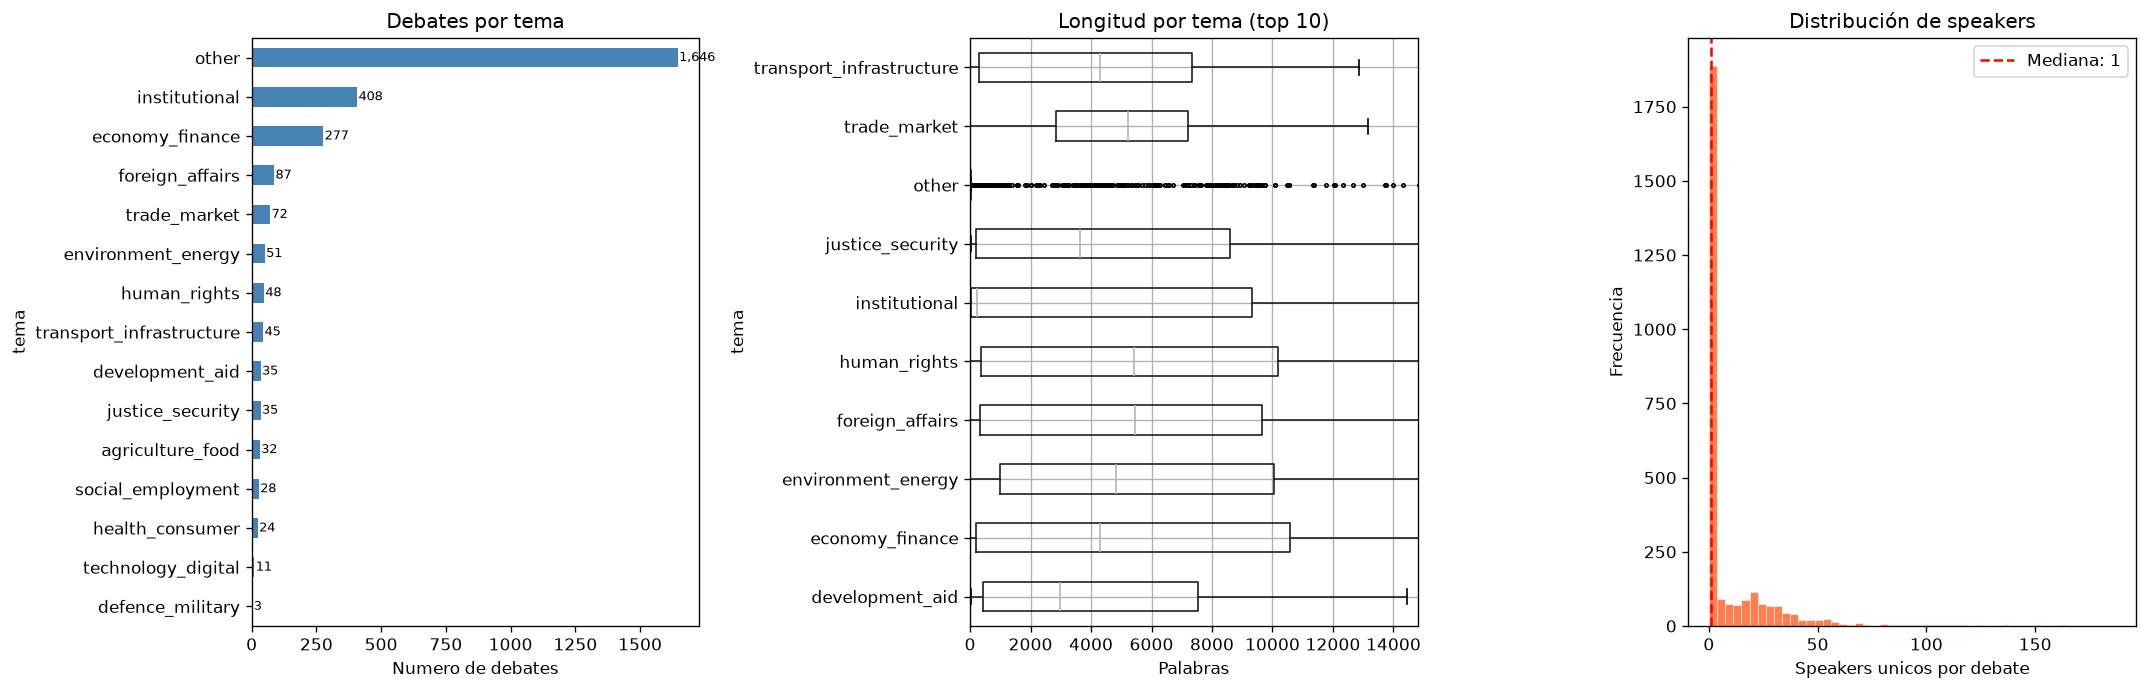

In [7]:
# Gráficas de temas y speakers
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Barplot de temas
ax = axes[0]
tema_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Numero de debates")
ax.set_title("Debates por tema")
ax.invert_yaxis()
for i, (count, tema) in enumerate(zip(tema_counts.values, tema_counts.index)):
    ax.text(count + 5, i, f"{count:,}", va="center", fontsize=8)

# Boxplot de palabras por tema
ax = axes[1]
top_temas = tema_counts.head(10).index.tolist()
df_top = df_content[df_content["tema"].isin(top_temas)]
df_top.boxplot(column="palabras", by="tema", ax=ax, vert=False, flierprops=dict(markersize=2))
ax.set_xlabel("Palabras")
ax.set_title("Longitud por tema (top 10)")
ax.set_xlim(0, df_content["palabras"].quantile(0.95))
plt.suptitle("")

# Distribución de speakers por debate
ax = axes[2]
ax.hist(df_content["speakers_unicos"], bins=50, color="coral", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Speakers unicos por debate")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de speakers")
ax.axvline(df_content["speakers_unicos"].median(), color="red", linestyle="--",
           label=f'Mediana: {df_content["speakers_unicos"].median():.0f}')
ax.legend()

plt.tight_layout()
plt.show()

## 5. Estimación de costos

In [8]:
# Estimación de tokens (~4 chars/token para inglés)
df_content["tokens_est"] = (df_content["chars_texto"] / 4).astype(int)

# Pipeline: 3 traductores + 1 reviewer + 1 evaluador + metadata
PIPELINE_MULTIPLIER = 12

# Precios (USD / 1M tokens promedio input+output)
# Weighted: ~60% cheap models, ~30% reviewer (gpt-4.1), ~10% ollama
AVG_COST_PER_1M = 0.60 * 1.00 + 0.30 * 5.00 + 0.10 * 0.0  # $2.10/M tokens

df_content["costo_est_usd"] = df_content["tokens_est"] * PIPELINE_MULTIPLIER * AVG_COST_PER_1M / 1_000_000

print("ESTIMACIÓN DE COSTOS POR RANGO")
print("=" * 80)
cost_by_range = df_content.groupby("rango_palabras", observed=False).agg(
    archivos=("file", "count"),
    tokens_total=("tokens_est", "sum"),
    costo_total=("costo_est_usd", "sum"),
    costo_medio=("costo_est_usd", "mean"),
).reset_index()
cost_by_range["tokens_total"] = cost_by_range["tokens_total"].map(lambda x: f"{x:,.0f}")
cost_by_range["costo_total"] = cost_by_range["costo_total"].map(lambda x: f"${x:,.2f}")
cost_by_range["costo_medio"] = cost_by_range["costo_medio"].map(lambda x: f"${x:,.4f}")
print(cost_by_range.to_string(index=False))

print(f"\n{'─' * 80}")
print(f"Costo estimado TOTAL (todos):        ${df_content['costo_est_usd'].sum():,.2f} USD")
print(f"Costo estimado promedio por debate:   ${df_content['costo_est_usd'].mean():,.4f} USD")

ESTIMACIÓN DE COSTOS POR RANGO
rango_palabras  archivos tokens_total costo_total costo_medio
          <100      1594       40,998       $1.03     $0.0006
       100-300       212       54,334       $1.37     $0.0065
       300-500        76       42,563       $1.07     $0.0141
        500-1K        56       57,348       $1.45     $0.0258
         1K-2K        40       88,219       $2.22     $0.0556
         2K-5K       223    1,227,618      $30.94     $0.1387
        5K-10K       324    3,645,465      $91.87     $0.2835
       10K-20K       188    3,723,564      $93.83     $0.4991
       20K-50K        69    3,037,759      $76.55     $1.1094
          50K+        20    2,207,089      $55.62     $2.7809

────────────────────────────────────────────────────────────────────────────────
Costo estimado TOTAL (todos):        $355.95 USD
Costo estimado promedio por debate:   $0.1270 USD


## 6. Selección de 1,000 debates

### Estrategia: muestreo estratificado por tema y tamaño

**Criterios de filtrado:**
- Descartar debates con **< 500 palabras** (contenido procedural, sin sustancia)
- Descartar debates con **> 15,000 palabras** (muy costosos)
- Rango util: **500-15K palabras**

**Criterios de muestreo (1,000 debates):**
- Muestreo **proporcional por tema**
- Dentro de cada tema, muestreo **estratificado por tamaño** (bins)

In [15]:
# ── Parámetros de selección (ajustables) ──
MIN_PALABRAS = 200
MAX_PALABRAS = 25_000
N_SELECCION = 1010
SEED = 42

# Filtrar rango útil
df_filtrado = df_content[(df_content["palabras"] >= MIN_PALABRAS) & (df_content["palabras"] <= MAX_PALABRAS)].copy()
print(f"Debates en rango [{MIN_PALABRAS:,}-{MAX_PALABRAS:,}] palabras: {len(df_filtrado):,} / {len(df_content):,}")
print(f"Descartados: {len(df_content) - len(df_filtrado):,} ({(len(df_content) - len(df_filtrado)) / len(df_content) * 100:.1f}%)")

if len(df_filtrado) < N_SELECCION:
    print(f"\nADVERTENCIA: Solo {len(df_filtrado)} debates disponibles, menos que {N_SELECCION} solicitados.")
    print("Ajusta MIN_PALABRAS o MAX_PALABRAS si es necesario.")

# Bins de tamaño
size_bins = [MIN_PALABRAS, 1000, 2000, 4000, 8000, MAX_PALABRAS + 1]
size_labels = ["small (500-1K)", "medium (1K-2K)", "med-large (2K-4K)",
               "large (4K-8K)", "xlarge (8K-15K)"]
df_filtrado["bin_size"] = pd.cut(df_filtrado["palabras"], bins=size_bins, labels=size_labels, right=False)

print(f"\nDistribucion del pool filtrado:")
print("-" * 55)
for tema in sorted(df_filtrado["tema"].unique()):
    n = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<28} {n:>5,}  ({n/len(df_filtrado)*100:>5.1f}%)")

Debates en rango [200-25,000] palabras: 1,006 / 2,802
Descartados: 1,796 (64.1%)

ADVERTENCIA: Solo 1006 debates disponibles, menos que 1010 solicitados.
Ajusta MIN_PALABRAS o MAX_PALABRAS si es necesario.

Distribucion del pool filtrado:
-------------------------------------------------------
  agriculture_food                28  (  2.8%)
  defence_military                 1  (  0.1%)
  development_aid                 28  (  2.8%)
  economy_finance                206  ( 20.5%)
  environment_energy              43  (  4.3%)
  foreign_affairs                 68  (  6.8%)
  health_consumer                 16  (  1.6%)
  human_rights                    37  (  3.7%)
  institutional                  166  ( 16.5%)
  justice_security                26  (  2.6%)
  other                          264  ( 26.2%)
  social_employment               21  (  2.1%)
  technology_digital               9  (  0.9%)
  trade_market                    59  (  5.9%)
  transport_infrastructure        34  (  3.4%)


In [16]:
# Muestreo estratificado: proporcional por tema, dentro de cada tema por tamaño
rng = np.random.default_rng(SEED)

# Calcular cuota por tema (proporcional)
tema_fracs = df_filtrado["tema"].value_counts(normalize=True)
tema_cuotas = (tema_fracs * N_SELECCION).round().astype(int)
# Ajustar si la suma no da exacto
diff = N_SELECCION - tema_cuotas.sum()
if diff != 0:
    tema_cuotas.iloc[0] += diff

print("Cuotas por tema:")
print("-" * 55)
for tema, cuota in tema_cuotas.items():
    pool = len(df_filtrado[df_filtrado["tema"] == tema])
    print(f"  {tema:<28} {cuota:>4} / {pool:>5,} disponibles")
print(f"  {'TOTAL':<28} {tema_cuotas.sum():>4}")

# Ejecutar muestreo
seleccionados = []
for tema, cuota in tema_cuotas.items():
    pool_tema = df_filtrado[df_filtrado["tema"] == tema]
    if len(pool_tema) <= cuota:
        seleccionados.append(pool_tema)
        continue

    muestras_tema = []
    bin_counts = pool_tema["bin_size"].value_counts()
    bin_fracs = bin_counts / bin_counts.sum()
    bin_cuotas = (bin_fracs * cuota).round().astype(int)
    diff_bin = cuota - bin_cuotas.sum()
    if diff_bin != 0:
        bin_cuotas.iloc[0] += diff_bin

    for bin_label, bin_cuota in bin_cuotas.items():
        pool_bin = pool_tema[pool_tema["bin_size"] == bin_label]
        n_sample = min(bin_cuota, len(pool_bin))
        if n_sample > 0:
            muestra = pool_bin.sample(n=n_sample, random_state=SEED)
            muestras_tema.append(muestra)

    if muestras_tema:
        tema_df = pd.concat(muestras_tema)
        if len(tema_df) < cuota:
            faltantes = cuota - len(tema_df)
            restantes = pool_tema[~pool_tema.index.isin(tema_df.index)]
            extra = restantes.sample(n=min(faltantes, len(restantes)), random_state=SEED)
            tema_df = pd.concat([tema_df, extra])
        seleccionados.append(tema_df)

df_seleccion = pd.concat(seleccionados).reset_index(drop=True)
print(f"\nSeleccionados: {len(df_seleccion):,} debates")

Cuotas por tema:
-------------------------------------------------------
  other                         266 /   264 disponibles
  economy_finance               207 /   206 disponibles
  institutional                 167 /   166 disponibles
  foreign_affairs                68 /    68 disponibles
  trade_market                   59 /    59 disponibles
  environment_energy             43 /    43 disponibles
  human_rights                   37 /    37 disponibles
  transport_infrastructure       34 /    34 disponibles
  development_aid                28 /    28 disponibles
  agriculture_food               28 /    28 disponibles
  justice_security               26 /    26 disponibles
  social_employment              21 /    21 disponibles
  health_consumer                16 /    16 disponibles
  technology_digital              9 /     9 disponibles
  defence_military                1 /     1 disponibles
  TOTAL                        1010

Seleccionados: 1,006 debates


## 7. Validación de la selección

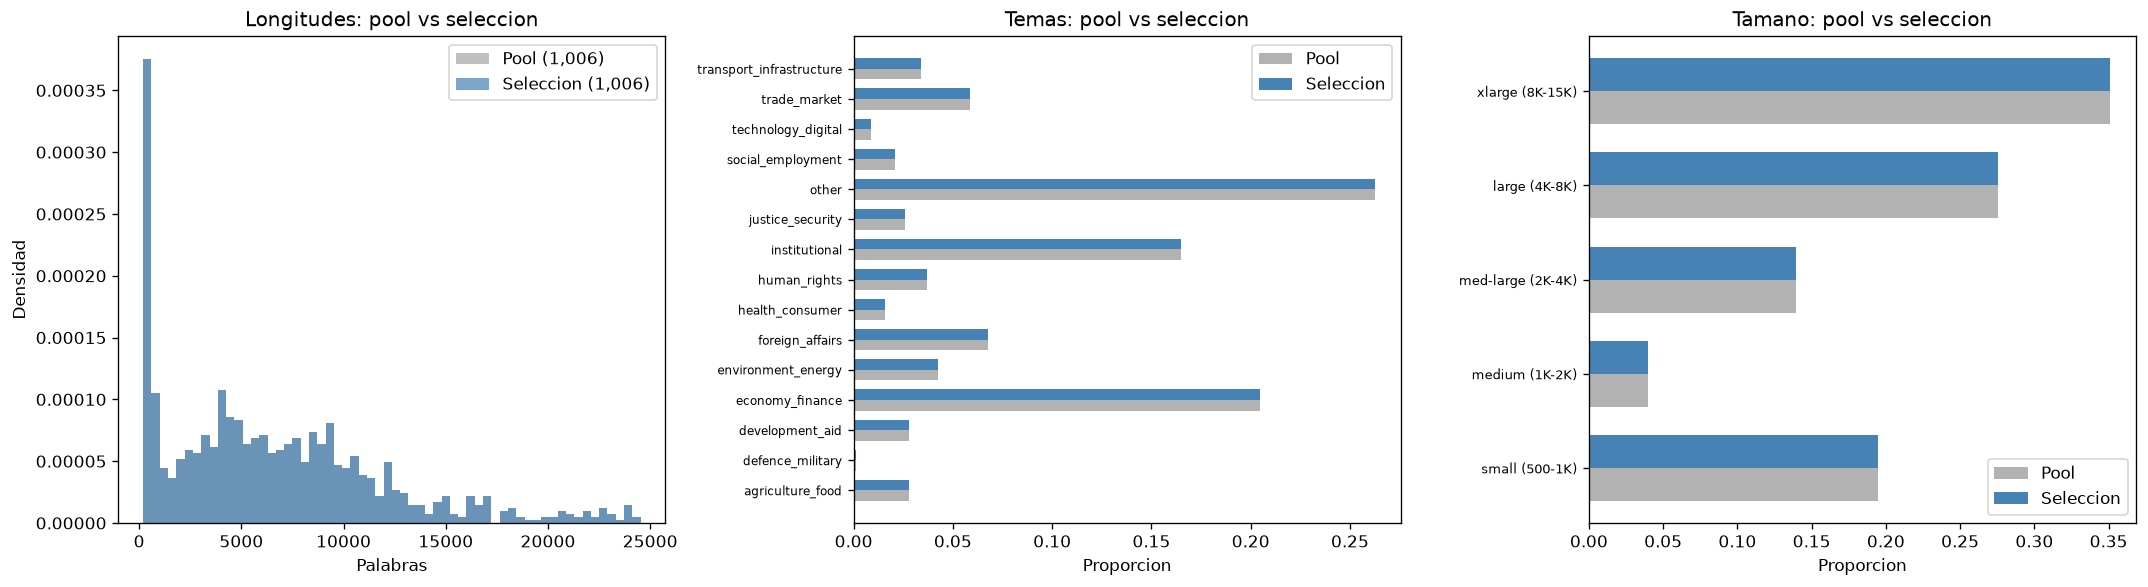


RESUMEN DE LA SELECCION
Debates seleccionados:     1,006
Palabras totales:          6,644,742
Tokens estimados:          9,974,523
Costo estimado pipeline:   $251.36 USD
Rango de palabras:         [201 - 24,529]
Temas representados:       15
Media palabras/debate:     6,605
Mediana palabras/debate:   5,584
Media speakers/debate:     22.0


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Comparar distribución de palabras
ax = axes[0]
ax.hist(df_filtrado["palabras"], bins=60, alpha=0.5, label=f"Pool ({len(df_filtrado):,})", color="gray", density=True)
ax.hist(df_seleccion["palabras"], bins=60, alpha=0.7, label=f"Seleccion ({len(df_seleccion):,})", color="steelblue", density=True)
ax.set_xlabel("Palabras")
ax.set_ylabel("Densidad")
ax.set_title("Longitudes: pool vs seleccion")
ax.legend()

# Comparar distribución de temas
ax = axes[1]
pool_temas = df_filtrado["tema"].value_counts(normalize=True).sort_index()
sel_temas = df_seleccion["tema"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_temas))
w = 0.35
ax.barh(x - w/2, pool_temas.values, w, label="Pool", color="gray", alpha=0.6)
ax.barh(x + w/2, sel_temas.reindex(pool_temas.index, fill_value=0).values, w, label="Seleccion", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_temas.index, fontsize=7)
ax.set_xlabel("Proporcion")
ax.set_title("Temas: pool vs seleccion")
ax.legend()

# Distribución por bin de tamaño
ax = axes[2]
pool_bins = df_filtrado["bin_size"].value_counts(normalize=True).sort_index()
sel_bins = df_seleccion["bin_size"].value_counts(normalize=True).sort_index()
x = np.arange(len(pool_bins))
ax.barh(x - w/2, pool_bins.values, w, label="Pool", color="gray", alpha=0.6)
ax.barh(x + w/2, sel_bins.reindex(pool_bins.index, fill_value=0).values, w, label="Seleccion", color="steelblue")
ax.set_yticks(x)
ax.set_yticklabels(pool_bins.index, fontsize=8)
ax.set_xlabel("Proporcion")
ax.set_title("Tamano: pool vs seleccion")
ax.legend()

plt.tight_layout()
plt.show()

# Estadísticas resumen
print("\nRESUMEN DE LA SELECCION")
print("=" * 60)
print(f"Debates seleccionados:     {len(df_seleccion):,}")
print(f"Palabras totales:          {df_seleccion['palabras'].sum():,}")
print(f"Tokens estimados:          {df_seleccion['tokens_est'].sum():,}")
print(f"Costo estimado pipeline:   ${df_seleccion['costo_est_usd'].sum():,.2f} USD")
print(f"Rango de palabras:         [{df_seleccion['palabras'].min():,} - {df_seleccion['palabras'].max():,}]")
print(f"Temas representados:       {df_seleccion['tema'].nunique()}")
print(f"Media palabras/debate:     {df_seleccion['palabras'].mean():,.0f}")
print(f"Mediana palabras/debate:   {df_seleccion['palabras'].median():,.0f}")
print(f"Media speakers/debate:     {df_seleccion['speakers_unicos'].mean():,.1f}")

## 8. Exportar archivos seleccionados

Copia los 1,000 archivos `.txt` seleccionados a `data/Europarl/selected/` y genera un CSV con metadatos.

In [18]:
OUTPUT_DIR = Path("../data/Europarl/selected")
OUTPUT_CSV = Path("europarl_seleccion_1000.csv")

# Crear directorio (limpiar si existe)
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True)

# Copiar archivos seleccionados
df_sel_sorted = df_seleccion.sort_values("file")
copied = 0
for _, row in df_sel_sorted.iterrows():
    src = EN_DIR / row["file"]
    dst = OUTPUT_DIR / row["file"]
    if src.exists():
        shutil.copy2(src, dst)
        copied += 1

total_size = sum(f.stat().st_size for f in OUTPUT_DIR.glob("*.txt"))
print(f"Archivos copiados a: {OUTPUT_DIR}")
print(f"  Total: {copied:,} archivos")
print(f"  Tamano: {total_size / (1024**2):.1f} MB")

# Verificar
n_files = len(list(OUTPUT_DIR.glob("*.txt")))
print(f"  Verificacion: {n_files} archivos en directorio")

# Exportar CSV con metadatos
cols_export = ["file", "chapter_id", "titulo", "palabras", "chars_texto",
               "speakers_total", "speakers_unicos", "tema", "bin_size",
               "tokens_est", "costo_est_usd"]
df_sel_sorted[cols_export].to_csv(OUTPUT_CSV, index=False, encoding="utf-8")
print(f"\nCSV de metadatos: {OUTPUT_CSV}")

print(f"\nListo para ejecutar:")
print(f"  python3 agente_europarl.py -i {OUTPUT_DIR}")

Archivos copiados a: ../data/Europarl/selected
  Total: 1,006 archivos
  Tamano: 39.7 MB
  Verificacion: 1006 archivos en directorio

CSV de metadatos: europarl_seleccion_1000.csv

Listo para ejecutar:
  python3 agente_europarl.py -i ../data/Europarl/selected
